# Sign-Language Safe House Lock
**Author:** Adeyemi Tobiloba Moses | **Dataset:** Kaggle ASL Alphabet (87,000 images, 29 classes)

This notebook builds a door lock that opens when an agent spells their safe word in ASL. It has two parts: a **recognizer** (one hand photo → one of 29 signs) and an **access system** (a sequence of signs → open or stay shut, and log who entered).

**Contents:** 1. Setup and data exploration · 2. Data preparation · 3. Recognizer training · 4. Evaluation (test set and own photos) · 5. The lock · 6. Demo scenarios · 7. Letter accuracy vs word accuracy

## 1. Setup and data exploration
The first cell is Kaggle's default starter: it loads the base libraries and lists the files in the attached datasets.

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

### 1.1 Locating the data
Finds the training folder, lists the 29 classes (A–Z, `space`, `del`, `nothing`), and checks that a GPU is available for training.

In [2]:
import os, glob

# Find the training folder
for root, dirs, files in os.walk('/kaggle/input'):
    if 'A' in dirs and 'del' in dirs:
        TRAIN_DIR = root
        break
print("Train dir:", TRAIN_DIR)

classes = sorted(os.listdir(TRAIN_DIR))
print(len(classes), "classes:", classes)

import torch
print("GPU available:", torch.cuda.is_available())

Train dir: /kaggle/input/datasets/grassknoted/asl-alphabet/asl_alphabet_train/asl_alphabet_train
29 classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
GPU available: True


### 1.2 Class balance
Counts the images in each class. Result: every class has exactly 3,000 images (87,000 in total), so the dataset is **perfectly balanced** and accuracy is not distorted by one class dominating.

count      29.0
mean     3000.0
std         0.0
min      3000.0
25%      3000.0
50%      3000.0
75%      3000.0
max      3000.0
dtype: float64
Total images: 87000


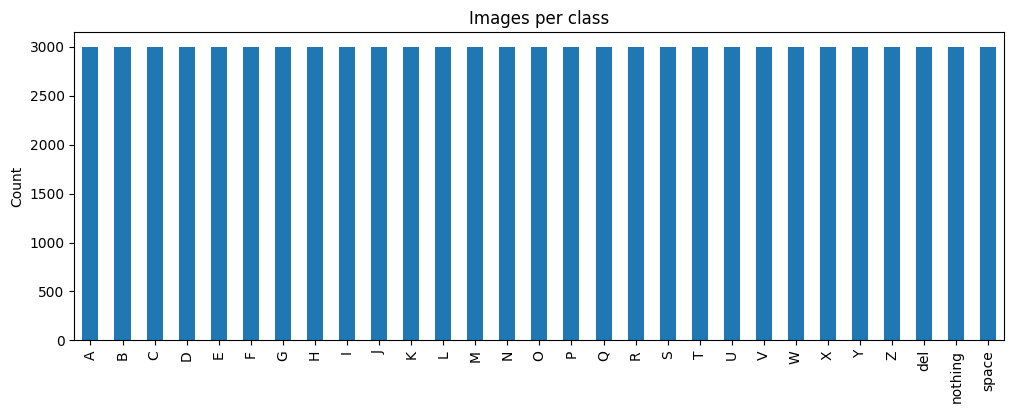

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

counts = {c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in classes}
df_counts = pd.Series(counts)
print(df_counts.describe())
print("Total images:", df_counts.sum())

df_counts.plot(kind='bar', figsize=(12,4), title='Images per class')
plt.ylabel('Count'); plt.show()

### 1.3 Sample images
Three random images from six classes (A, M, N, S, space, nothing). Observations: lighting varies noticeably between images, the backgrounds are fairly simple, and all the images appear to be of **one signer's hand**. That limits how well the model should generalise to other people, which the own-photo test later confirms. Visually similar signs: A/M/N/S/T (closed fists differing by thumb position), U/V/R, and K/P.

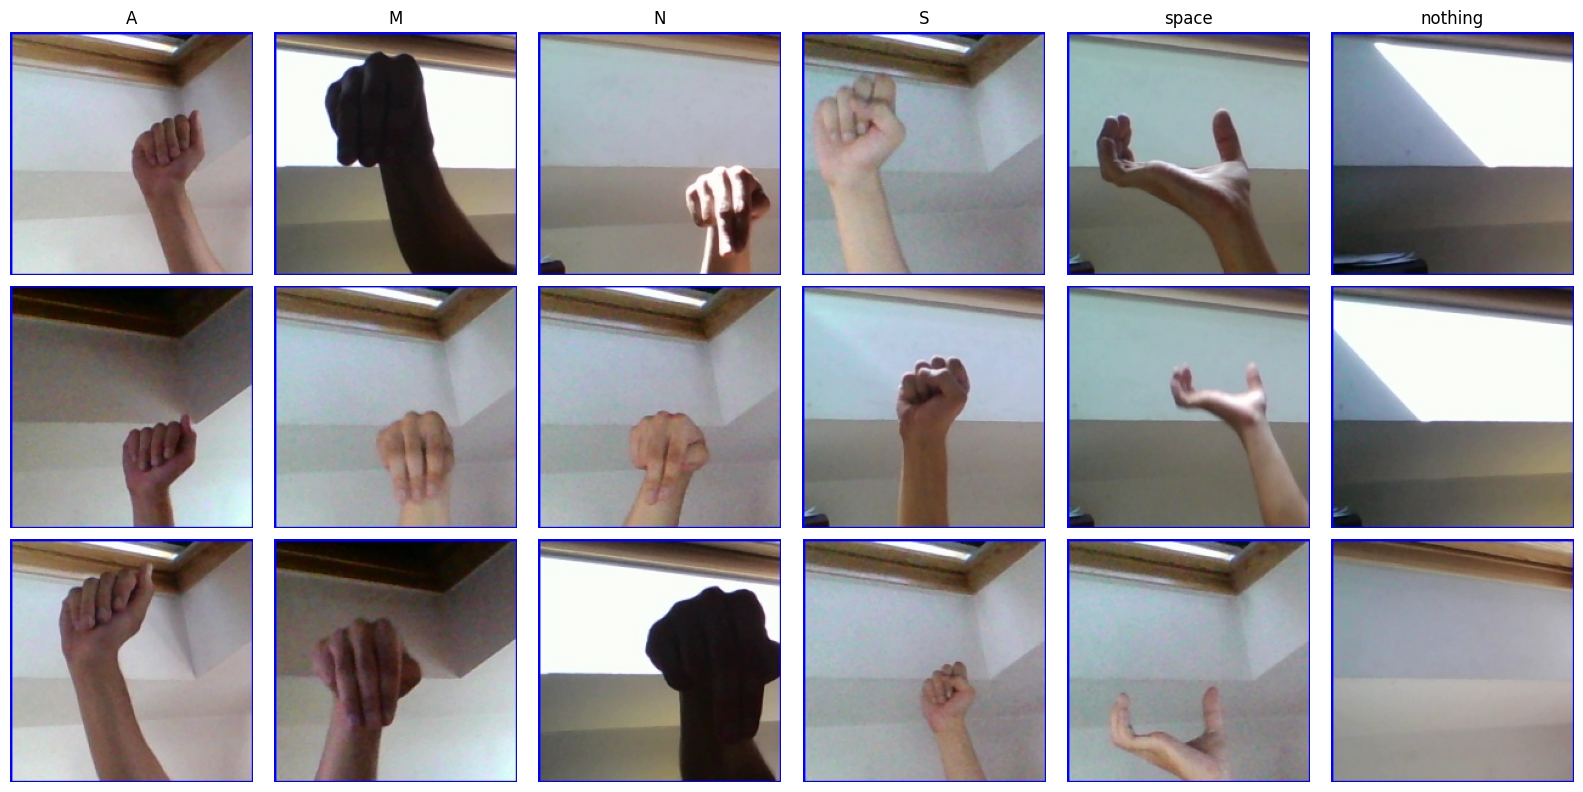

In [6]:
from PIL import Image
import random

sample_classes = ['A', 'M', 'N', 'S', 'space', 'nothing']
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for col, c in enumerate(sample_classes):
    files = random.sample(os.listdir(os.path.join(TRAIN_DIR, c)), 3)
    for row, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(c)
plt.tight_layout(); plt.show()

### 1.4 Framing the problem
**Likely confusions:** A/M/N/S/T (closed fists that differ by thumb position), U/V/R (two raised fingers, differing in spread or crossing), and K/P (same hand shape, different orientation).

**Classes the lock needs:**
- **A–Z:** needed, because safe words are made of letters.
- **`nothing`:** means no hand is in view, so the lock waits instead of guessing a letter. It can also act as a separator between letters.
- **`del`:** lets an agent correct a mistake by removing the previous letter, instead of failing the whole attempt.
- **`space`:** not needed, because every safe word is a single word. It is ignored.

**Problem 1, recognition:** the input is one 200 × 200 colour photo of a hand; the output is one of 29 labels together with a confidence score for each.

**Problem 2, access:** the input is a sequence of recognised signs. The rules are: `del` removes the previous letter, `nothing` and `space` are ignored, and a low-confidence letter triggers a retry. The resulting word must exactly match a registered safe word. A match grants access and logs the agent ID, codename and time; otherwise the door stays shut and the failed attempt is logged.

## 2. Data preparation
- **Subset:** 600 random images per class (17,400 in total, fixed seed) so training is fast on a free GPU.
- **Split:** 70% train / 15% validation / 15% test, stratified so each class is equally represented. The test set is used only once, for the final evaluation.
- **Augmentation (training only):** small rotations and brightness/contrast changes to cope with lighting. No horizontal flips, since that would turn a right hand into a left hand.

**Caveat:** the images come from video frames of one signer, so near-duplicate frames can land on both sides of the split, which inflates test accuracy.

In [7]:
import numpy as np, torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# 1. Sample 600 images per class
rows = []
for c in classes:
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))
    for f in random.sample(files, 600):
        rows.append((os.path.join(TRAIN_DIR, c, f), c))
df = pd.DataFrame(rows, columns=['path', 'label'])

class_to_idx = {c: i for i, c in enumerate(classes)}
df['y'] = df['label'].map(class_to_idx)

# 2. Stratified 70/15/15 split
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['y'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['y'], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

# 3. Transforms
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(), norm])

class ASLDataset(Dataset):
    def __init__(self, df, tf): self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(r.path).convert('RGB')), r.y

train_dl = DataLoader(ASLDataset(train_df, train_tf), batch_size=64, shuffle=True, num_workers=2)
val_dl   = DataLoader(ASLDataset(val_df, eval_tf), batch_size=64, num_workers=2)
test_dl  = DataLoader(ASLDataset(test_df, eval_tf), batch_size=64, num_workers=2)

12180 2610 2610


## 3. The recognizer: transfer learning with ResNet18
A ResNet18 pretrained on ImageNet, with its last layer replaced by 29 outputs. **Why:** the network already detects edges and shapes, so it only has to adapt to hand signs. That works well with a few hundred images per class and trains in minutes. A from-scratch CNN would need much more data and time for similar results.

Trained for 6 epochs (Adam, learning-rate decay); the best checkpoint by validation accuracy is saved as `best_model.pt`. Validation accuracy reached 100%, a sign that the validation set is very close to the training data.

In [8]:
import torch.nn as nn
from torchvision import models
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))  # 29 outputs
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)

def run_epoch(dl, train):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

EPOCHS = 6
best_val = 0
for ep in range(EPOCHS):
    t = time.time()
    tr_loss, tr_acc = run_epoch(train_dl, True)
    va_loss, va_acc = run_epoch(val_dl, False)
    scheduler.step()
    print(f"Epoch {ep+1}/{EPOCHS} | train acc {tr_acc:.3f} | val acc {va_acc:.3f} | {time.time()-t:.0f}s")
    if va_acc > best_val:
        best_val = va_acc
        torch.save(model.state_dict(), 'best_model.pt')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


Epoch 1/6 | train acc 0.933 | val acc 0.978 | 101s
Epoch 2/6 | train acc 0.984 | val acc 0.977 | 46s
Epoch 3/6 | train acc 0.989 | val acc 0.989 | 49s
Epoch 4/6 | train acc 0.998 | val acc 1.000 | 48s
Epoch 5/6 | train acc 1.000 | val acc 1.000 | 48s
Epoch 6/6 | train acc 1.000 | val acc 1.000 | 48s


## 4. Evaluation on the held-out test set
Loads the best checkpoint and evaluates on the 2,610 test images it never trained on. Reports overall accuracy, per-class precision and recall, the confusion matrix and the misclassified images.

**Result:** 99.85% accuracy with only 4 errors: N→M, R→U, Z→S and del→S. The first two are the look-alike pairs predicted earlier. Z is a motion letter, so a still frame can resemble another sign. Because of near-duplicate frames, this number overstates real-world performance.

TEST ACCURACY: 0.9985

              precision    recall  f1-score   support

           A      1.000     1.000     1.000        90
           B      1.000     1.000     1.000        90
           C      1.000     1.000     1.000        90
           D      1.000     1.000     1.000        90
           E      1.000     1.000     1.000        90
           F      1.000     1.000     1.000        90
           G      1.000     1.000     1.000        90
           H      1.000     1.000     1.000        90
           I      1.000     1.000     1.000        90
           J      1.000     1.000     1.000        90
           K      1.000     1.000     1.000        90
           L      1.000     1.000     1.000        90
           M      0.989     1.000     0.994        90
           N      1.000     0.989     0.994        90
           O      1.000     1.000     1.000        90
           P      1.000     1.000     1.000        90
           Q      1.000     1.000     1.000        90
    

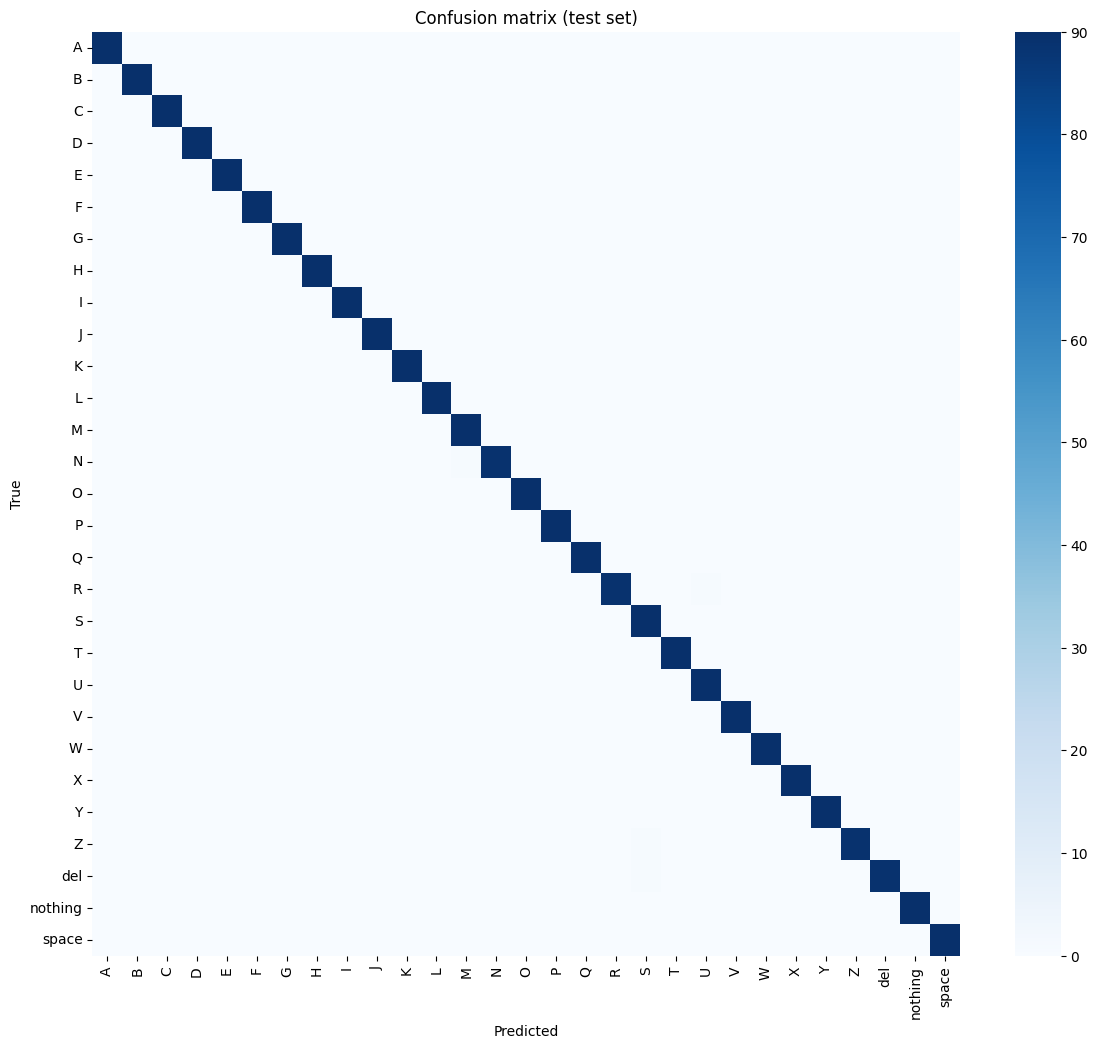

Number of errors: 4
(del, S)    1
(Z, S)      1
(R, U)      1
(N, M)      1
Name: count, dtype: int64


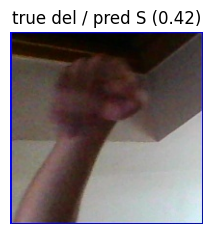

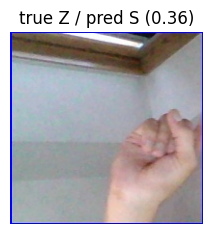

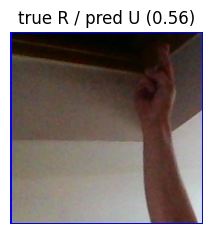

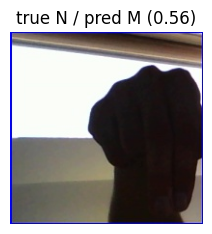

In [9]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

model.load_state_dict(torch.load('best_model.pt'))
model.eval()

all_preds, all_labels, all_conf = [], [], []
with torch.no_grad():
    for x, y in test_dl:
        probs = torch.softmax(model(x.to(device)), dim=1).cpu()
        conf, pred = probs.max(1)
        all_preds += pred.tolist(); all_labels += y.tolist(); all_conf += conf.tolist()

all_preds, all_labels, all_conf = map(np.array, (all_preds, all_labels, all_conf))
test_acc = accuracy_score(all_labels, all_preds)
print(f"TEST ACCURACY: {test_acc:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=classes, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap='Blues', annot=False)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test set)')
plt.show()

# Most confused pairs + wrong images
errors = np.where(all_preds != all_labels)[0]
print("Number of errors:", len(errors))
pairs = pd.Series([(classes[all_labels[i]], classes[all_preds[i]]) for i in errors]).value_counts()
print(pairs.head(10))

for i in errors[:6]:
    r = test_df.reset_index(drop=True).iloc[i]
    plt.figure(figsize=(2.5, 2.5)); plt.imshow(Image.open(r.path)); plt.axis('off')
    plt.title(f"true {classes[all_labels[i]]} / pred {classes[all_preds[i]]} ({all_conf[i]:.2f})")
    plt.show()

### 4.1 Real-world test: my own photos
11 photos of my own hand (A, B, C, K, L ×2, R, U, V, W, Y) with my own background and lighting, run through the model.

**Result:** 7/11 correct (63.64%), against 99.85% on the test set. Misreads: B→W (0.51), C→H (0.87), K→space (0.85), V→K (0.985). **Why the gap:** the training data is a single signer in consistent settings, and my hand, skin tone, background, lighting and camera distance are all new to the model. Three of the four errors came with high confidence, so the model is overconfident on unfamiliar input.

['A.jpeg', 'B.jpeg', 'C.jpeg', 'K.jpeg', 'L.jpeg', 'L_2.jpeg', 'R.jpeg', 'U.jpeg', 'V.jpeg', 'W.jpeg', 'Y.jpeg']
    file true  pred  conf                                  top3  correct
  A.jpeg    A     A 0.876     [(A, 0.88), (T, 0.05), (L, 0.03)]     True
  B.jpeg    B     W 0.511      [(W, 0.51), (M, 0.3), (B, 0.13)]    False
  C.jpeg    C     H 0.872 [(H, 0.87), (Q, 0.04), (space, 0.04)]    False
  K.jpeg    K space 0.851 [(space, 0.85), (I, 0.11), (R, 0.01)]    False
  L.jpeg    L     L 0.642      [(L, 0.64), (V, 0.1), (F, 0.07)]     True
L_2.jpeg    L     L 0.692     [(L, 0.69), (V, 0.14), (F, 0.06)]     True
  R.jpeg    R     R 1.000    [(R, 1.0), (U, 0.0), (space, 0.0)]     True
  U.jpeg    U     U 0.990       [(U, 0.99), (K, 0.0), (R, 0.0)]     True
  V.jpeg    V     K 0.985      [(K, 0.99), (V, 0.01), (G, 0.0)]    False
  W.jpeg    W     W 0.919     [(W, 0.92), (K, 0.02), (I, 0.02)]     True
  Y.jpeg    Y     Y 0.998        [(Y, 1.0), (I, 0.0), (D, 0.0)]     True

Own-photo 

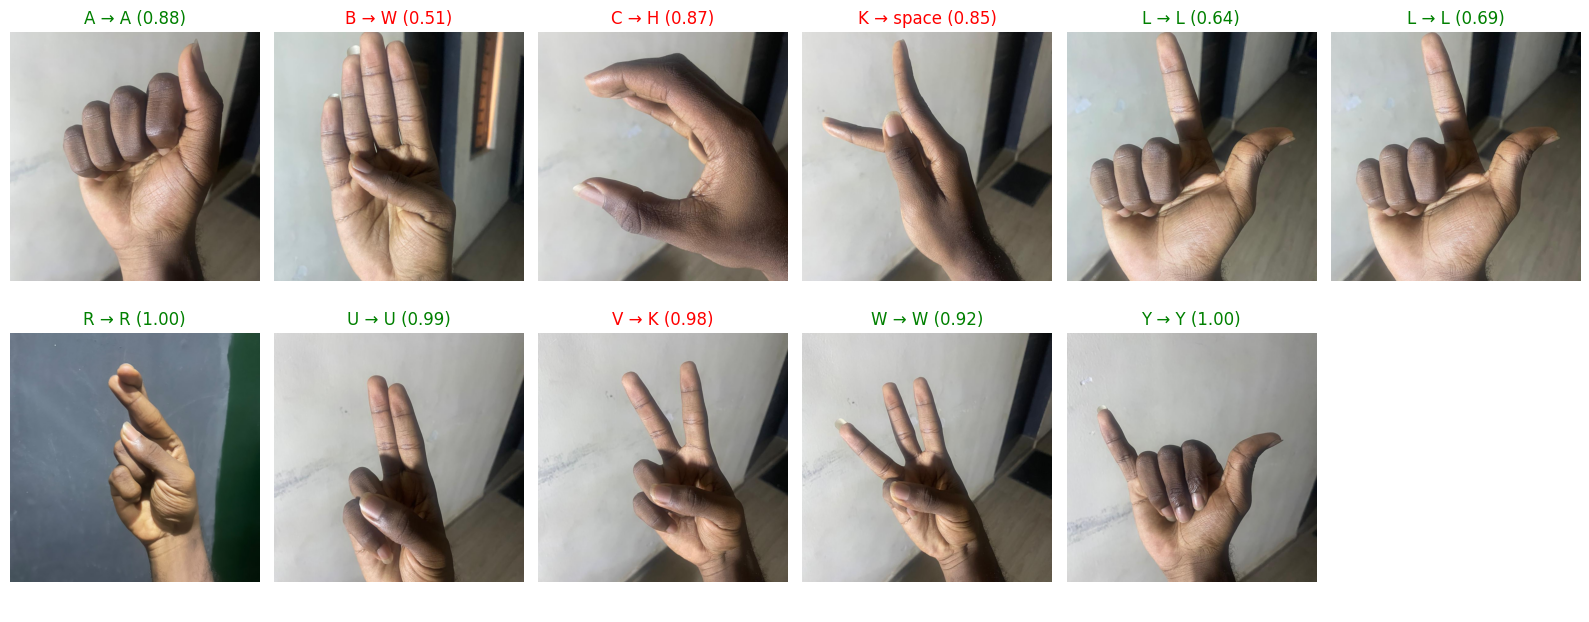

In [14]:
import re
from PIL import ImageOps

PHOTO_DIR = '/kaggle/input/datasets/tobilobamadeyemi/my-asl-photos3'
print(sorted(os.listdir(PHOTO_DIR)))   # should list 11 files, including R

def load_photo(path):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img).convert('RGB')   # fix phone rotation
    w, h = img.size
    s = min(w, h)                                        # center-crop to square
    return img.crop(((w - s)//2, (h - s)//2, (w + s)//2, (h + s)//2))

model.eval()
results = []
for f in sorted(os.listdir(PHOTO_DIR)):
    if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue
    true = re.match(r'[A-Za-z]', f).group(0).upper()
    img = load_photo(os.path.join(PHOTO_DIR, f))
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    top3 = probs.topk(3)
    pred = classes[top3.indices[0]]
    results.append({'file': f, 'true': true, 'pred': pred,
                    'conf': round(top3.values[0].item(), 3),
                    'top3': [(classes[i], round(p.item(), 2)) for p, i in zip(top3.values, top3.indices)],
                    'correct': pred == true})

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))
print(f"\nOwn-photo accuracy: {res_df.correct.mean():.2%} ({res_df.correct.sum()}/{len(res_df)})")

# Show the photos with predictions
n = len(results)
cols = 6
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(16, 3.2 * rows))
for ax in axes.flat:
    ax.axis('off')
for ax, r in zip(axes.flat, results):
    ax.imshow(load_photo(os.path.join(PHOTO_DIR, r['file'])))
    ax.set_title(f"{r['true']} → {r['pred']} ({r['conf']:.2f})",
                 color='green' if r['correct'] else 'red')
plt.tight_layout(); plt.show()

## 5. The lock
### 5.1 Choosing the confidence threshold
Compares thresholds on the test set and on my own photos: how many correct letters are still accepted, and how many wrong ones slip through.

**Choice: 0.90.** On the test set, no wrong letter is accepted from 0.70 upward, and 0.90 still accepts 99.8% of correct letters. On my own photos, raising the threshold from 0.70 to 0.90 cuts wrong letters let through from 3/4 to 1/4, at the cost of rejecting 3 of the 7 correct letters. This follows the head of security's priority (re-signing is better than letting the wrong person in) while limiting how often real agents are turned away.

**Limitation:** on real photos the model is overconfident (V→K at 0.985 passed the threshold), so the threshold alone cannot make the lock safe.

In [15]:
rows = []
for t in [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]:
    acc = all_conf >= t
    rows.append({
        'threshold': t,
        'test: correct accepted %': round(((all_preds == all_labels) & acc).sum() / (all_preds == all_labels).sum() * 100, 1),
        'test: wrong accepted': int(((all_preds != all_labels) & acc).sum()),
        'own: correct accepted': f"{((res_df.correct) & (res_df.conf >= t)).sum()}/{res_df.correct.sum()}",
        'own: wrong accepted': f"{((~res_df.correct) & (res_df.conf >= t)).sum()}/{(~res_df.correct).sum()}",
    })
print(pd.DataFrame(rows).to_string(index=False))

 threshold  test: correct accepted %  test: wrong accepted own: correct accepted own: wrong accepted
      0.50                     100.0                     2                   7/7                 4/4
      0.70                     100.0                     0                   5/7                 3/4
      0.80                     100.0                     0                   5/7                 3/4
      0.90                      99.8                     0                   4/7                 1/4
      0.95                      99.6                     0                   3/7                 1/4
      0.99                      98.7                     0                   3/7                 0/4


### 5.2 Lock logic
- `nothing`: ignored (no hand in view).
- `del`: removes the previous letter.
- `space`: ignored, since safe words are single words (a misread as `space` makes the word too short, which fails safely).
- Confidence below 0.90: the door stays shut, the agent is asked to sign again, and a `RETRY` is logged.
- The word must match a registered safe word **exactly** (no fuzzy matching). A match grants access and logs agent ID, codename and time; otherwise the door stays shut and the failed attempt is logged.

Ends with a smoke test: BRAVO signed with test images grants access to AG-001 Falcon.

In [16]:
from datetime import datetime

REGISTRY = {
    'BRAVO':  ('AG-001', 'Falcon'),
    'CIPHER': ('AG-002', 'Nightjar'),
    'DELTA':  ('AG-003', 'Wraith'),
    'EMBER':  ('AG-004', 'Kestrel'),
    'QUIET':  ('AG-005', 'Lynx'),
}
THRESHOLD = 0.90      # adjust after reading the Cell A table
LOG = []

def predict_image(path):
    x = eval_tf(load_photo(path)).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
    conf, idx = probs.max(0)
    return classes[idx], conf.item()

def log_event(outcome, word, agent, reason):
    entry = {'time': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
             'outcome': outcome,
             'agent_id': agent[0] if agent else '-',
             'codename': agent[1] if agent else '-',
             'word_read': word, 'reason': reason}
    LOG.append(entry)
    return entry

def attempt(image_paths, threshold=None):
    threshold = THRESHOLD if threshold is None else threshold
    letters = []
    print("--- New attempt ---")
    for p in image_paths:
        label, conf = predict_image(p)
        note = ''
        if label == 'nothing':
            note = 'ignored (no hand)'
        elif conf < threshold:
            print(f"  {os.path.basename(p)} -> {label} ({conf:.2f})  LOW CONFIDENCE")
            e = log_event('RETRY', ''.join(letters), None, f'low confidence on a letter (<{threshold})')
            print("  DOOR STAYS SHUT: please sign again.", e['time'])
            return 'RETRY'
        elif label == 'del':
            removed = letters.pop() if letters else None
            note = f'deleted {removed}'
        elif label == 'space':
            note = 'ignored (space)'
        else:
            letters.append(label)
        print(f"  {os.path.basename(p)} -> {label} ({conf:.2f})  {note}")

    word = ''.join(letters)
    if word in REGISTRY:
        agent = REGISTRY[word]
        e = log_event('GRANTED', word, agent, 'safe word matched')
        print(f"  ACCESS GRANTED: {agent[0]} {agent[1]} at {e['time']}")
        return 'GRANTED'
    e = log_event('DENIED', word, None, 'no registered safe word matches')
    print(f"  ACCESS DENIED (read '{word}') at {e['time']}")
    return 'DENIED'

# Smoke test with held-out test images
def pick(label):
    return test_df[test_df.label == label].sample(1).path.iloc[0]

attempt([pick(c) for c in 'BRAVO'])

--- New attempt ---
  B462.jpg -> B (1.00)  
  R2561.jpg -> R (1.00)  
  A1508.jpg -> A (1.00)  
  V2905.jpg -> V (1.00)  
  O167.jpg -> O (1.00)  
  ACCESS GRANTED: AG-001 Falcon at 2026-10-06 21:38:42


'GRANTED'

## 6. Demo scenarios
1. All five agents sign their own safe words: all granted with the correct agent logged.
2. An unregistered word (ALPHA): denied and logged.
3. A mistake corrected with `del` (DELTA): the wrong Z is removed, then access is granted.
4. A real misread (my own V photo read as K at 0.99): the word becomes BRAKO and is denied. The exact-match rule caught it, not the threshold.
5. Extras: a low-confidence letter (my B photo, 0.51) triggers a retry, and `nothing` frames between letters are ignored.

The entry log at the end records every attempt.

In [17]:
np.random.seed(7)   # makes the random test-image picks repeatable

def own(letter):
    return os.path.join(PHOTO_DIR, f"{letter}.jpeg")

def sign(word):
    """Pick one held-out test image per letter."""
    return [pick(c) for c in word]

# ---- Scenario 1: each registered agent signs their own safe word ----
print("\n=== SCENARIO 1: all five agents ===")
for w in ['BRAVO', 'CIPHER', 'DELTA', 'EMBER', 'QUIET']:
    attempt(sign(w))

# ---- Scenario 2: a word that is not in the registry ----
print("\n=== SCENARIO 2: unregistered word (ALPHA) ===")
attempt(sign('ALPHA'))

# ---- Scenario 3: agent makes a mistake and corrects it with del ----
# Intends DELTA, signs D, E, then a wrong Z, deletes it, then continues L, T, A
print("\n=== SCENARIO 3: mistake corrected with del (DELTA) ===")
attempt([pick('D'), pick('E'), pick('Z'), pick('del'),
         pick('L'), pick('T'), pick('A')])

# ---- Scenario 4: the model misreads a letter (real misclassified photo) ----
# BRAVO, but the V is my own photo, which the model reads as K with 0.985 confidence
print("\n=== SCENARIO 4: confident misread (own V photo read as K) ===")
attempt([pick('B'), pick('R'), pick('A'), own('V'), pick('O')])

# ---- Extra: low-confidence letter triggers a retry ----
# Own B photo was read as W with only 0.51 confidence
print("\n=== EXTRA: low-confidence letter (own B photo) ===")
attempt([own('B'), pick('R'), pick('A'), pick('V'), pick('O')])

# ---- Extra: nothing between letters is ignored ----
print("\n=== EXTRA: 'nothing' frames between letters (QUIET) ===")
attempt([pick('Q'), pick('nothing'), pick('U'), pick('I'),
         pick('nothing'), pick('E'), pick('T')])

# ---- The audit log ----
print("\n=== ENTRY LOG ===")
print(pd.DataFrame(LOG).to_string(index=False))


=== SCENARIO 1: all five agents ===
--- New attempt ---
  B1104.jpg -> B (1.00)  
  R865.jpg -> R (1.00)  
  A2600.jpg -> A (1.00)  
  V1853.jpg -> V (1.00)  
  O239.jpg -> O (1.00)  
  ACCESS GRANTED: AG-001 Falcon at 2026-10-06 21:41:09
--- New attempt ---
  C446.jpg -> C (1.00)  
  I417.jpg -> I (1.00)  
  P2547.jpg -> P (1.00)  
  H1069.jpg -> H (1.00)  
  E1095.jpg -> E (1.00)  
  R2378.jpg -> R (1.00)  
  ACCESS GRANTED: AG-002 Nightjar at 2026-10-06 21:41:09
--- New attempt ---
  D1139.jpg -> D (1.00)  
  E333.jpg -> E (1.00)  
  L264.jpg -> L (1.00)  
  T1050.jpg -> T (1.00)  
  A616.jpg -> A (1.00)  
  ACCESS GRANTED: AG-003 Wraith at 2026-10-06 21:41:10
--- New attempt ---
  E2120.jpg -> E (1.00)  
  M2831.jpg -> M (1.00)  
  B977.jpg -> B (1.00)  
  E2891.jpg -> E (1.00)  
  R526.jpg -> R (1.00)  
  ACCESS GRANTED: AG-004 Kestrel at 2026-10-06 21:41:10
--- New attempt ---
  Q1011.jpg -> Q (1.00)  
  U266.jpg -> U (1.00)  
  I570.jpg -> I (1.00)  
  E1202.jpg -> E (1.00)  
 

## 7. Letter accuracy versus word accuracy
If each letter is read correctly with probability *p*, a 5-letter word is read correctly with probability p⁵.
- Test set: p = 0.9985 → 99.2% of 5-letter words.
- My own photos: p = 0.6364 → only 10.4% of words.

To reach 95% of words correct the recognizer needs about 99% letter accuracy; for 99% of words, about 99.8%. Small per-letter errors compound quickly. Caveats: my own-photo figure rests on only 11 photos, and the formula assumes errors are independent, whereas real errors cluster by hand, lighting and background.

In [18]:
p_test = accuracy_score(all_labels, all_preds)   # 0.9985
p_own  = res_df.correct.mean()                   # 7/11

print(f"p (test set)   = {p_test:.4f} -> 5-letter word: {p_test**5:.1%}")
print(f"p (own photos) = {p_own:.4f} -> 5-letter word: {p_own**5:.1%}")

print("\nLetter accuracy needed for a given word accuracy (5 letters):")
for target in [0.90, 0.95, 0.99]:
    print(f"  {target:.0%} of words correct -> need p >= {target**(1/5):.4f}")

p (test set)   = 0.9985 -> 5-letter word: 99.2%
p (own photos) = 0.6364 -> 5-letter word: 10.4%

Letter accuracy needed for a given word accuracy (5 letters):
  90% of words correct -> need p >= 0.9791
  95% of words correct -> need p >= 0.9898
  99% of words correct -> need p >= 0.9980
